In [46]:
#!pip install tensorflow
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split

In [47]:
planilha = pd.read_excel('Frantz.xlsx')
planilha

,Concurso,Bola1,Bola2,Bola3,Bola4,Bola5,Bola6,Bola7,Bola8,Bola9,Bola10,Bola11,Bola12,Bola13,Bola14,Bola15
0,1,2,3,5,6,9,10,11,13,14,16,18,20,23,24,25
1,2,1,4,5,6,7,9,11,12,13,15,16,19,20,23,24
2,3,1,4,6,7,8,9,10,11,12,14,16,17,20,23,24
3,4,1,2,4,5,8,10,12,13,16,17,18,19,23,24,25
4,5,1,2,4,8,9,11,12,13,15,16,19,20,23,24,25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2290,2653,2,3,7,8,9,10,12,13,14,15,17,18,19,20,21
2291,2654,1,3,5,6,9,10,13,15,16,17,19,20,21,24,25
2292,2655,1,5,6,8,9,11,13,14,15,16,19,20,21,22,23
2293,2656,2,3,4,7,9,10,11,12,13,17,18,19,20,21,25


In [48]:
XX = planilha['Concurso'].values
X = np.zeros((len(XX), 1))
X[:,0] = XX
X

array([[1.000e+00],
       [2.000e+00],
       [3.000e+00],
       ...,
       [2.655e+03],
       [2.656e+03],
       [2.657e+03]])

In [49]:
Y = planilha.drop(labels=['Concurso'], axis=1).values
Y

array([[ 2,  3,  5, ..., 23, 24, 25],
       [ 1,  4,  5, ..., 20, 23, 24],
       [ 1,  4,  6, ..., 20, 23, 24],
       ...,
       [ 1,  5,  6, ..., 21, 22, 23],
       [ 2,  3,  4, ..., 20, 21, 25],
       [ 1,  2,  3, ..., 17, 21, 24]])

In [50]:
Y.shape[1]

15

In [51]:
X.shape[1]

1

In [52]:
 tf.random.set_seed(42)
X_train, X_test, Y_train, Y_test = train_test_split(X,  Y, test_size=0.33)
model = tf.keras.Sequential([
tf.keras.layers.Dense(Y.shape[1], input_shape=(X.shape[1],), activation='relu')])
# tf.keras.layers.Dense(Y.shape[1], activation='relu'),
# tf.keras.layers.Dense(Y.shape[1], activation='relu'),,
# tf.keras.layers.Dense(Y.shape[1], activation='sigmoid')])

model.compile(loss=tf.keras.losses.mse,
                  optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  metrics=["mse", "mae"])

history = model.fit(X, Y, verbose=0, epochs=5000)
print("treinada...")



treinada...


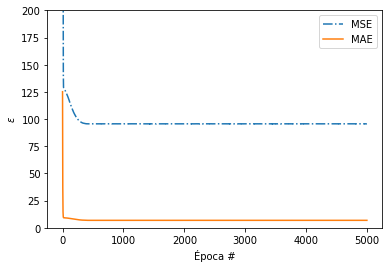

In [53]:
fig_hist, ax_hist = plt.subplots()
ax_hist.plot(history.history["mse"], label="MSE", ls='-.')
ax_hist.plot(history.history["mae"], label="MAE")
ax_hist.set_xlabel("Época #")
ax_hist.set_ylabel(r"$\varepsilon$")
ax_hist.set_ylim(-0.1, 200)
ax_hist.legend()

In [54]:
Y_pred = model.predict([2])
erro = Y_pred - Y
erro[1]

1/1 [==============================] - 0s 45ms/step


array([  0.53562975,  -4.        ,  -5.        ,  -6.        ,
        -7.        ,   0.78826237,   0.40121651,   1.02236557,
       -13.        , -15.        , -16.        ,   0.52880287,
       -20.        ,  -0.10717964,   0.3652916 ])